# Selective Decarbonization
## Selective Decarbonization: A Triple-Difference Analysis of Heterogeneous Greenhouse Gas Responses to the EU ETS (1990–2014)

### Research Question
The **EU Emissions Trading System (EU ETS)** was launched in 2005 and, during its early phases, primarily regulated **CO₂ emissions from stationary installations**, particularly in the power sector and energy-intensive industries. In contrast, **CH₄, N₂O, HFCs, PFCs, and SF₆** were largely outside the system's direct regulatory scope until its coverage was gradually expanded, particularly in **Phase 3 (from 2013)**.

This study asks:

> **Did countries exposed to the EU ETS experience a systematic reduction in CO₂ emissions relative to greenhouse gases that were not yet directly regulated, compared with countries outside the EU ETS?**

## Identification Strategy

The study employs a **Triple-Difference (DDD)** design across three dimensions:

* **Country** (*i*)
* **Greenhouse gas** (*g*)
* **Year** (*t*)

The main variable of interest is:

```text
Treated_i × Post_t × Regulated_g
```

where `Treated_i` identifies countries exposed to the EU ETS, `Post_t` indicates the post-EU ETS period, and `Regulated_g` identifies greenhouse gases directly regulated by the policy.

The model includes three sets of two-way fixed effects:

* `country × gas`
* `country × year`
* `gas × year`

This saturated fixed-effects specification ensures that the DDD coefficient is identified from variation occurring **simultaneously across all three dimensions: country, greenhouse gas, and time**.

### Baseline Model

$$
Y_{igt} =
\beta\,(Treated_i \times Post_t \times Regulated_g)
+ \alpha_{ig}
+ \gamma_{it}
+ \delta_{gt}
+ \varepsilon_{igt}
$$

## Research Structure

1. **Data Cleaning & Exploratory Data Analysis (EDA)**
2. **EU ETS Policy Exposure**
3. **Treatment and Control Groups**
4. **Baseline Triple-Difference Model**
5. **Event Study & Parallel Trends**
6. **Robustness Checks**
7. **Heterogeneity Across Greenhouse Gases**
8. **Results & Policy Implications**

## Data

The study uses the **UN Greenhouse Gas Inventory Data** from the **United Nations Framework Convention on Climate Change (UNFCCC)**.

The dataset contains greenhouse gas emissions by:

**Country × Year × Greenhouse Gas**

* **43 Annex I countries**
* **1990–2014**
* Unit: **kt CO₂-equivalent**



In [1]:
!pip install pyfixest


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# ============================================================
# SETUP
# ============================================================
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import pyfixest as pf

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

RAW_PATH = "greenhouse_gas_inventory_data_data.csv"
np.random.seed(42)


# Step 1 - Data Cleaning & EDA

The raw data are provided in **long format**, where each row represents a `(country_or_area, year, category, value)` observation. The `category` variable includes both **individual greenhouse gases** and **aggregated GHG indicators**.

The first step is to examine the dataset structure and assess the **time and country coverage** of each `category`. The data are then standardized into a **country × year × gas panel** for subsequent analysis.

In [3]:
raw = pd.read_csv(RAW_PATH)
print("Shape:", raw.shape)
print("Number of countries/areas:", raw.country_or_area.nunique(), "| Number of years:", raw.year.nunique(),
      f"({raw.year.min()}-{raw.year.max()})")
print("Duplicate rows:", raw.duplicated().sum())
raw.head(10)


Shape: (8406, 4)
Number of countries/areas: 43 | Number of years: 25 (1990-2014)
Duplicate rows: 0


,country_or_area,year,value,category
0,Australia,2014,393126.946994,carbon_dioxide_co2_emissions_without_land_use_...
1,Australia,2013,396913.936530,carbon_dioxide_co2_emissions_without_land_use_...
2,Australia,2012,406462.847704,carbon_dioxide_co2_emissions_without_land_use_...
3,Australia,2011,403705.528314,carbon_dioxide_co2_emissions_without_land_use_...
4,Australia,2010,406200.993184,carbon_dioxide_co2_emissions_without_land_use_...
5,Australia,2009,408448.479000,carbon_dioxide_co2_emissions_without_land_use_...
6,Australia,2008,404237.828214,carbon_dioxide_co2_emissions_without_land_use_...
7,Australia,2007,398816.453544,carbon_dioxide_co2_emissions_without_land_use_...
8,Australia,2006,391134.100909,carbon_dioxide_co2_emissions_without_land_use_...
9,Australia,2005,385581.132806,carbon_dioxide_co2_emissions_without_land_use_...


In [4]:
# Check coverage for each category: number of reporting countries,
# year range, and number of observations
coverage = (raw.groupby("category")
              .agg(n_countries=("country_or_area", "nunique"),
                   year_min=("year", "min"), year_max=("year", "max"),
                   n_rows=("value", "size"))
              .sort_values("n_rows", ascending=False))
coverage.index = [c[:60] + "..." if len(c) > 60 else c for c in coverage.index]
coverage


,n_countries,year_min,year_max,n_rows
carbon_dioxide_co2_emissions_without_land_use_land_use_chang...,43,1990,2014,1074
greenhouse_gas_ghgs_emissions_without_land_use_land_use_chan...,43,1990,2014,1074
nitrous_oxide_n2o_emissions_without_land_use_land_use_change...,43,1990,2014,1074
methane_ch4_emissions_without_land_use_land_use_change_and_f...,43,1990,2014,1074
sulphur_hexafluoride_sf6_emissions_in_kilotonne_co2_equivale...,43,1990,2014,1032
hydrofluorocarbons_hfcs_emissions_in_kilotonne_co2_equivalen...,42,1990,2014,975
greenhouse_gas_ghgs_emissions_including_indirect_co2_without...,38,1990,2014,949
perfluorocarbons_pfcs_emissions_in_kilotonne_co2_equivalent,38,1990,2014,831
nitrogen_trifluoride_nf3_emissions_in_kilotonne_co2_equivale...,14,1990,2014,248
unspecified_mix_of_hydrofluorocarbons_hfcs_and_perfluorocarb...,3,1990,2014,75


## Data Coverage

The dataset contains **10 categories** in total. These include **2 aggregated GHG indicators**, which represent total greenhouse gas emissions under different accounting definitions, and **8 individual greenhouse gases**.

Among these categories, **NF₃** has limited data coverage, with only **14 out of 43 countries** reporting observations. The **unspecified mix of HFCs/PFCs** is even more limited, with data available for only **3 countries**.

Because these two categories have very few observations, including them in the main analysis would result in a highly unbalanced panel and could make comparisons between the treated and control groups less reliable.

Therefore, the **main analysis focuses on six greenhouse gases: CO₂, CH₄, N₂O, HFCs, PFCs, and SF₆**. NF₃ and the unspecified HFCs/PFCs category are excluded from the main regression and will instead be discussed as **data limitations** in Step 8.

 **Emission Unit** : All categories are reported in **kilotonnes of CO₂-equivalent (kt CO₂e)**. Since the data are already expressed in a common CO₂-equivalent unit, **no additional manual GWP conversion is required**.



In [5]:
# Check whether the sum of the 6 individual gases matches the reported GHG total

GAS_MAP = {
    "carbon_dioxide_co2_emissions_without_land_use_land_use_change_and_forestry_lulucf_in_kilotonne_co2_equivalent": "CO2",
    "methane_ch4_emissions_without_land_use_land_use_change_and_forestry_lulucf_in_kilotonne_co2_equivalent": "CH4",
    "nitrous_oxide_n2o_emissions_without_land_use_land_use_change_and_forestry_lulucf_in_kilotonne_co2_equivalent": "N2O",
    "hydrofluorocarbons_hfcs_emissions_in_kilotonne_co2_equivalent": "HFCs",
    "perfluorocarbons_pfcs_emissions_in_kilotonne_co2_equivalent": "PFCs",
    "sulphur_hexafluoride_sf6_emissions_in_kilotonne_co2_equivalent": "SF6",
}

TOTAL_KEY = "greenhouse_gas_ghgs_emissions_without_land_use_land_use_change_and_forestry_lulucf_in_kilotonne_co2_equivalent"

# Keep only the 6 individual gases
gas_long = raw[raw.category.isin(GAS_MAP)].copy()

# Convert the original category names into shorter gas names
gas_long["gas"] = gas_long["category"].map(GAS_MAP)

# Rename columns for easier use
gas_long = gas_long.rename(
    columns={
        "country_or_area": "country",
        "value": "emissions"
    }
)

# Calculate the total emissions from the 6 gases for each country and year
sum_gases = (
    gas_long.groupby(["country", "year"])["emissions"]
    .sum()
    .reset_index()
)

# Get the reported total GHG emissions
totals = raw[raw.category == TOTAL_KEY].rename(
    columns={
        "country_or_area": "country",
        "value": "emissions_total"
    }
)[["country", "year", "emissions_total"]]

# Compare the calculated total with the reported GHG total
recon = sum_gases.merge(
    totals,
    on=["country", "year"]
)

# Calculate the percentage difference
recon["diff_pct"] = (
    (recon.emissions - recon.emissions_total)
    / recon.emissions_total
    * 100
)

print(
    f"Compared {len(recon)} country-year pairs: "
    f"maximum absolute difference = {recon.diff_pct.abs().max():.2e}%"
)

print(
    "=> The sum of the 6 individual gases closely matches "
    "the reported GHG total, with only negligible floating-point differences."
)

Compared 1074 country-year pairs: maximum absolute difference = 5.16e-01%
=> The sum of the 6 individual gases closely matches the reported GHG total, with only negligible floating-point differences.


In [6]:
print("Minimum value across the 6 main gases:", gas_long.emissions.min())
print("Number of observations <= 0:", (gas_long.emissions <= 0).sum())
print("=> No zero or negative values are present in the original data.")

Minimum value across the 6 main gases: 1.10375e-06
Number of observations <= 0: 0
=> No zero or negative values are present in the original data.


## 1.1 Building the country × year × gas Panel

The panel is constructed using all 43 countries first, allowing us to examine the missing-data patterns objectively before restricting the sample to the treatment and control groups in Step 3.


In [7]:
ALL_COUNTRIES = sorted(gas_long.country.unique())

YEARS = list(range(1990, 2015))

# Create all possible country × year × gas combinations
full_idx = pd.MultiIndex.from_product(
    [ALL_COUNTRIES, YEARS, GAS_MAP.values()],
    names=["country", "year", "gas"]
)

# Convert the index into a DataFrame
panel_full = pd.DataFrame(index=full_idx).reset_index()

# Merge the observed emissions data
panel_full = panel_full.merge(
    gas_long[["country", "year", "gas", "emissions"]],
    on=["country", "year", "gas"],
    how="left"
)

# Check the total number of cells and missing values
print("Total cells (country × year × gas):", len(panel_full))

print(
    "Missing cells:",
    panel_full.emissions.isna().sum(),
    f"({panel_full.emissions.isna().mean()*100:.1f}%)"
)

Total cells (country × year × gas): 6450
Missing cells: 390 (6.0%)


In [8]:
# Classify missing values:
# (a) Missing for all 25 years → drop the country-gas pair
# (b) Partially missing for HFCs/PFCs/SF6 → fill missing values with 0
# (c) Partially missing for CO2/CH4/N2O → drop missing observations

miss_share = panel_full.groupby(["country", "gas"])["emissions"].apply(
    lambda s: s.isna().mean()
)

fully_missing_pairs = sorted(
    miss_share[miss_share == 1.0].index.tolist()
)

partially_missing = miss_share[
    (miss_share > 0) & (miss_share < 1.0)
].sort_values(ascending=False)

# Print fully missing pairs
print("=== 1. Country-Gas Pairs with No Data ===")
print(
    f"Total: {len(fully_missing_pairs)} pairs "
    f"(missing for all 25 years)"
)

for c, g in fully_missing_pairs:
    print(f"  - {c} / {g} → Drop")

# Create a clearer table for partially missing pairs
missing_table = partially_missing.reset_index()
missing_table.columns = ["country", "gas", "missing_share"]

missing_table["missing_years"] = (
    missing_table["missing_share"] * len(YEARS)
).round().astype(int)

missing_table["observed_years"] = (
    len(YEARS) - missing_table["missing_years"]
)

missing_table["missing_percent"] = (
    missing_table["missing_share"] * 100
).round(1)

missing_table["action"] = missing_table["gas"].apply(
    lambda x: "0"
    if x in ["HFCs", "PFCs", "SF6"]
    else "Drop missing observations"
)

print("\n=== 2. Partially Missing Country-Gas Pairs ===")
print(
    missing_table[
        [
            "country",
            "gas",
            "missing_years",
            "observed_years",
            "missing_percent",
            "action"
        ]
    ].head(15).to_string(index=False)
)

=== 1. Country-Gas Pairs with No Data ===
Total: 6 pairs (missing for all 25 years)
  - Belarus / HFCs → Drop
  - Belarus / PFCs → Drop
  - Cyprus / PFCs → Drop
  - Latvia / PFCs → Drop
  - Lithuania / PFCs → Drop
  - Luxembourg / PFCs → Drop

=== 2. Partially Missing Country-Gas Pairs ===
      country  gas  missing_years  observed_years  missing_percent action
      Estonia PFCs             22               3             88.0      0
     Bulgaria PFCs             18               7             72.0      0
      Croatia PFCs             17               8             68.0      0
        Malta PFCs             17               8             68.0      0
       Monaco PFCs             16               9             64.0      0
       Turkey HFCs             10              15             40.0      0
Liechtenstein  SF6              9              16             36.0      0
       Turkey PFCs              8              17             32.0      0
       Turkey  SF6              8          

### Missing Data Handling Rules

The following rules are applied consistently throughout the analysis:

1. **Completely missing `country × gas` pairs:**
   If a country has no observations for a particular gas during the entire 25-year period, the pair is excluded from the panel. These missing values are treated as **unobserved**, rather than as zero emissions.

2. **Partially missing HFCs, PFCs, and SF₆:**
   For these industrial gases, partially missing observations are treated as **zero emissions** and filled with `0`. This is considered reasonable when the missing values may reflect periods when the country had little or no relevant emitting activity, such as before certain industrial activities were established or after relevant facilities were shut down.

3. **Partially missing CO₂, CH₄, and N₂O:**
   Missing values for these gases are **not** replaced with zero because they are generally present across economies. Instead, the missing observations are excluded from the analysis. The number of such observations is very small and mainly involves a single year for Monaco.

In [9]:
FILL_ZERO_GASES = {"HFCs", "PFCs", "SF6"}


def build_gas_panel(df_raw, countries, years=YEARS):
    
    # Keep the 6 main gases
    sub = df_raw[df_raw.category.isin(GAS_MAP)].copy()
    
    # Convert category names to short gas names
    sub["gas"] = sub["category"].map(GAS_MAP)
    
    # Rename columns
    sub = sub.rename(
        columns={
            "country_or_area": "country",
            "value": "emissions_kt_co2eq"
        }
    )
    
    # Keep only selected countries
    sub = sub[
        sub.country.isin(countries)
    ][
        ["country", "year", "gas", "emissions_kt_co2eq"]
    ]

    # Create a complete country × year × gas panel
    idx = pd.MultiIndex.from_product(
        [countries, years, GAS_MAP.values()],
        names=["country", "year", "gas"]
    )

    p = (
        pd.DataFrame(index=idx)
        .reset_index()
        .merge(
            sub,
            on=["country", "year", "gas"],
            how="left"
        )
    )

    # Find country-gas pairs with no data for all years
    miss_all = p.groupby(
        ["country", "gas"]
    )["emissions_kt_co2eq"].apply(
        lambda s: s.isna().all()
    )

    drop_pairs = set(
        miss_all[miss_all].index
    )

    # Remove country-gas pairs with no data at all
    if drop_pairs:
        pair_col = list(zip(p.country, p.gas))
        p = p[
            [pr not in drop_pairs for pr in pair_col]
        ].copy()

    # For HFCs, PFCs, and SF6, treat partial missing values as zero
    fmask = (
        p.gas.isin(FILL_ZERO_GASES)
        & p.emissions_kt_co2eq.isna()
    )

    n_filled = fmask.sum()

    p.loc[
        fmask,
        "emissions_kt_co2eq"
    ] = 0.0

    # Count remaining missing observations
    # These are mainly missing CO2, CH4, or N2O observations
    n_dropped_obs = p.emissions_kt_co2eq.isna().sum()

    # Remove the remaining missing observations
    p = p.dropna(
        subset=["emissions_kt_co2eq"]
    ).reset_index(drop=True)

    # Apply the inverse hyperbolic sine transformation
    # This transformation can handle zero values
    p["y_ihs"] = np.arcsinh(
        p.emissions_kt_co2eq
    )

    return (
        p,
        drop_pairs,
        n_filled,
        n_dropped_obs
    )


# Build the panel using all 43 countries
panel_all, dropped_pairs_all, n_filled_all, n_dropped_all = (
    build_gas_panel(raw, ALL_COUNTRIES)
)

print(
    f"Full panel (43 countries): {len(panel_all)} observations | "
    f"Excluded {len(dropped_pairs_all)} country-gas pairs | "
    f"Filled {n_filled_all} missing observations with 0 | "
    f"Excluded {n_dropped_all} remaining missing observations"
)

Full panel (43 countries): 6297 observations | Excluded 6 country-gas pairs | Filled 237 missing observations with 0 | Excluded 3 remaining missing observations


In [10]:
# Check which observations would remain missing after the same rules
check = panel_full.copy()

# Remove completely missing country-gas pairs
check = check[
    ~check.set_index(["country", "gas"]).index.isin(dropped_pairs_all)
].copy()

# Fill missing values for HFCs, PFCs, and SF6
mask = (
    check["gas"].isin(FILL_ZERO_GASES)
    & check["emissions"].isna()
)

check.loc[mask, "emissions"] = 0

# Show remaining missing observations
remaining_missing = check[
    check["emissions"].isna()
][["country", "year", "gas"]]

print("Remaining missing observations:")
print(remaining_missing.to_string(index=False))

Remaining missing observations:
country  year gas
 Monaco  2014 CO2
 Monaco  2014 CH4
 Monaco  2014 N2O


## 1.2 Emissions Trends by Gas and Pre-/Post-2005 Period

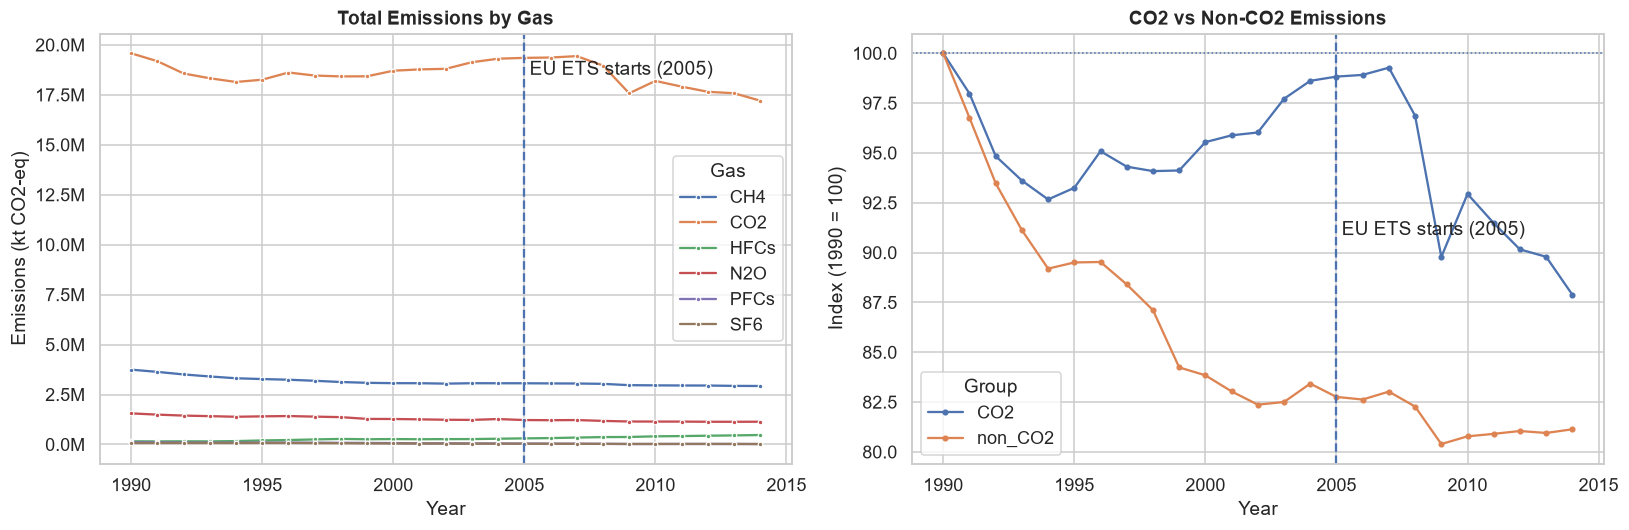

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# ==============================
# 1. Total emissions by gas
# ==============================

gas_trend = (
    panel_all.groupby(["year", "gas"])["emissions_kt_co2eq"]
    .sum()
    .reset_index()
)

sns.lineplot(
    data=gas_trend,
    x="year",
    y="emissions_kt_co2eq",
    hue="gas",
    marker="o",
    markersize=3,
    ax=axes[0]
)

axes[0].axvline(2005, linestyle="--", linewidth=1.5)
axes[0].text(
    2005.2,
    axes[0].get_ylim()[1] * 0.9,
    "EU ETS starts (2005)"
)

axes[0].set_title("Total Emissions by Gas")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Emissions (kt CO2-eq)")
axes[0].yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M")
)
axes[0].legend(title="Gas")


# ==============================
# 2. CO2 vs Non-CO2
# ==============================

piv = panel_all.pivot_table(
    index="year",
    columns="gas",
    values="emissions_kt_co2eq",
    aggfunc="sum"
)

piv["non_CO2"] = piv.drop(columns="CO2").sum(axis=1)

idx100 = (
    piv[["CO2", "non_CO2"]]
    / piv[["CO2", "non_CO2"]].iloc[0]
    * 100
)

idx100.plot(
    ax=axes[1],
    marker="o",
    markersize=3
)

axes[1].axhline(100, linestyle=":", linewidth=1)
axes[1].axvline(2005, linestyle="--", linewidth=1.5)

axes[1].text(
    2005.2,
    axes[1].get_ylim()[1] * 0.9,
    "EU ETS starts (2005)"
)

axes[1].set_title("CO2 vs Non-CO2 Emissions")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Index (1990 = 100)")
axes[1].legend(title="Group")

plt.tight_layout()
plt.show()

### Preliminary Observation

The preliminary trends show that **non-CO₂ emissions generally declined over the study period**, although the magnitude and timing of the decline may vary across gases and countries. These changes may reflect factors beyond the EU ETS, such as improvements in agricultural practices, waste management, and separate regulations targeting fluorinated gases.

**CO₂ emissions show a more noticeable decline after around 2008**, which coincides with the global financial crisis. Therefore, this decline cannot be attributed to the EU ETS based on the raw trends alone. Year fixed effects will be used in the subsequent analysis to account for common time shocks affecting countries.

These patterns are based on the **full sample of 43 countries** and are intended only as descriptive evidence. The main treatment and control groups will be defined in **Step 3**.



# Step 2 — EU ETS Policy Exposure

Rather than assuming that "CO₂ = regulated and all other gases = unregulated" throughout the entire period, we classify the actual scope of the EU Emissions Trading System (EU ETS) according to its successive **regulatory phases**, based on Directive 2003/87/EC and its subsequent amendments.

| Phase | Period | Actual greenhouse-gas coverage |
|---|---|---|
| **Phase 1** | 2005–2007 | **CO₂** from specified stationary installations, including combustion installations, oil refineries, coke ovens, iron and steel production, cement, glass, lime, ceramics, and pulp and paper. |
| **Phase 2** | 2008–2012 | Still predominantly **CO₂**. **N₂O from nitric acid production** was included by a number of Member States through opt-in mechanisms. Civil aviation was incorporated into the EU ETS from 2012, but this does not affect the gas classification used here. |
| **Phase 3** | 2013–2020 | The scope was expanded to additional greenhouse gases and activities, including **N₂O from nitric acid, adipic acid, glyoxal and glyoxylic acid production** and **PFCs from primary aluminium production**. |

The European Commission identifies CO₂ as the greenhouse gas covered during the initial phase. During Phase 2, N₂O emissions from nitric acid production were included by a number of countries. Phase 3 subsequently expanded the ETS to additional sectors and gases. :contentReference[oaicite:3]{index=3}

For the **1990–2014 study period**, **CH₄, HFCs, and SF₆ were not directly covered by the EU ETS for the activities considered here**. This does not mean that these gases were unregulated under EU climate policy; rather, they were addressed through other policy instruments and regulatory frameworks.

Based on this regulatory evolution, we construct the variable `Regulated_g` using two specifications throughout the notebook:

- **Baseline (2005 = Phase 1 / early Phase 2):**  
  `Regulated = {CO2}`  
  This reflects the core scope of the EU ETS at its launch and during most of the early period.

- **Robustness (2013 = Phase 3):**  
  `Regulated = {CO2, N2O, PFCs}`  
  This specification is used in Step 6 to test whether the results are sensitive to the subsequent expansion of the EU ETS to additional greenhouse gases and activities.

The greenhouse gases are therefore classified into three groups:

· **Directly covered from 2005:** CO₂  
· **Covered later and/or for specified activities:** N₂O, PFCs  
· **Not directly covered by the EU ETS during the study period:** CH₄, HFCs, SF₆

In [12]:
gas_classification = pd.DataFrame({
    "gas": ["CO2", "N2O", "PFCs", "CH4", "HFCs", "SF6"],
    "eu_ets_status": ["Directly covered (Phase 1, 2005)",
                       "Later/partially covered (Phase 3, 2013; NL opt-in 2010)",
                       "Later/partially covered (Phase 3, 2013 — primary aluminium)",
                       "Not directly covered (Effort Sharing / non-ETS)",
                       "Not directly covered (F-Gas Regulation, ngoài ETS)",
                       "Not directly covered (F-Gas Regulation, ngoài ETS)"],
    "regulated_baseline_2005": [1, 0, 0, 0, 0, 0],
    "regulated_phase3_2013":   [1, 1, 1, 0, 0, 0],
})
gas_classification


,gas,eu_ets_status,regulated_baseline_2005,regulated_phase3_2013
0,CO2,"Directly covered (Phase 1, 2005)",1,1
1,N2O,"Later/partially covered (Phase 3, 2013; NL opt...",0,1
2,PFCs,"Later/partially covered (Phase 3, 2013 — prima...",0,1
3,CH4,Not directly covered (Effort Sharing / non-ETS),0,0
4,HFCs,"Not directly covered (F-Gas Regulation, ngoài ...",0,0
5,SF6,"Not directly covered (F-Gas Regulation, ngoài ...",0,0


In [13]:
REGULATED_BASELINE = {"CO2"}
REGULATED_PHASE3   = {"CO2", "N2O", "PFCs"}


# Step 3 - Treatment and Control Groups

**Treatment group:** **EU-25** - the 25 EU Member States at the time the EU ETS was launched on **1 January 2005**. This group consisted of **15 existing Member States plus 10 countries that joined the EU in the 2004 enlargement**. All 25 countries entered the EU ETS in 2005. Therefore, in the baseline analysis, the **treatment timing is common across all treated countries**.

**Control group:** **UNFCCC Annex I countries** that were **outside the EU and did not participate in the EU ETS throughout the 2005–2014 study window**. The baseline control group consists of:

**Australia, Canada, Japan, New Zealand, Russia, Switzerland, Türkiye, Ukraine, the United States, Belarus, and Monaco.**

### Countries Excluded from the Baseline Sample

Some countries had different EU ETS entry dates from 2005. Including them directly in either the Treatment or Control group in the baseline specification would introduce **heterogeneous treatment timing** and complicate the identification of a common treatment effect.

- **Bulgaria and Romania:** joined the EU in 2007 and entered the EU ETS in 2007, rather than in 2005.
- **Croatia:** joined the EU in 2013 and entered the EU ETS in 2013.
- **Norway and Liechtenstein:** Although not EU Member States, these three European Economic Area (EEA) countries were officially incorporated into the EU ETS starting in **2008** (Phase 2), pursuant to EEA Joint Committee Decision No. 146/2007..
- **Iceland:** Regarding Iceland specifically, while legally integrated in 2008, the practical exposure to the EU ETS during **Phase 2 (2008–2012)** was **minimal**. This was due to Iceland's 100% renewable energy grid and the fact that primary aluminium production - its largest industrial emission source - was only brought under mandatory coverage in **Phase 3 (2013)**.

If these countries were included in the baseline Control group throughout 2005–2014, some control units would become **exposed to the EU ETS during the study period**, violating the assumption of an untreated control group.

Therefore, in the **baseline analysis**, these countries are excluded to maintain a cleaner identification strategy: **the EU-25 begins treatment in 2005, while the Control group remains outside the EU ETS throughout the 2005–2014 study window**.

These countries are **not permanently excluded from the study**. They are reintroduced in **Step 6** for robustness checks, including:

- **Staggered-timing extension:** allows countries to enter treatment at different points in time.
- **Alternative control sets:** examines whether the results are sensitive to the choice of control group.

In [14]:
EU25 = ['Austria', 'Belgium', 'Cyprus', 'Czech Republic', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany',
        'Greece', 'Hungary', 'Ireland', 'Italy', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'Netherlands',
        'Poland', 'Portugal', 'Slovakia', 'Slovenia', 'Spain', 'Sweden', 'United Kingdom']

assert len(EU25) == 25

BASELINE_CONTROL = ['Australia', 'Canada', 'Japan', 'New Zealand', 'Russian Federation', 'Switzerland',
                    'Turkey', 'Ukraine', 'United States of America', 'Belarus', 'Monaco']

LATER_JOINERS = {
    'Bulgaria': 2007,
    'Romania': 2007,
    'Croatia': 2013
}  # EU accession -> EU ETS entry

EEA_JOINERS = {
    'Norway': 2008,
    'Iceland': 2013,
    'Liechtenstein': 2008
}  # EEA countries with different EU ETS entry timing

OECD_CONTROL = ['Australia', 'Canada', 'Japan', 'New Zealand', 'Switzerland', 'Turkey',
                'United States of America', 'Monaco']  # Excluding transition economies

print(f"Treatment group (EU-25): {len(EU25)} countries")
print(f"Control group (baseline): {len(BASELINE_CONTROL)} countries -> {BASELINE_CONTROL}")
print(f"Excluded from baseline (heterogeneous timing): {list(LATER_JOINERS) + list(EEA_JOINERS)}")

Treatment group (EU-25): 25 countries
Control group (baseline): 11 countries -> ['Australia', 'Canada', 'Japan', 'New Zealand', 'Russian Federation', 'Switzerland', 'Turkey', 'Ukraine', 'United States of America', 'Belarus', 'Monaco']
Excluded from baseline (heterogeneous timing): ['Bulgaria', 'Romania', 'Croatia', 'Norway', 'Iceland', 'Liechtenstein']


In [15]:
def add_treatment(panel, treated_entry, control_countries, treat_year_control, regulated_gases,
                  sample_start=1990, sample_end=2014):
    """
    treated_entry: dict {country: entry_year} allowing staggered treatment timing.
    control_countries: list of never-treated countries in the sample.
    treat_year_control: Post-treatment year for the control group
                        (typically aligned with the main policy benchmark, e.g. 2005).
    regulated_gases: set of gas codes considered "Regulated" under this specification.
    """
    p = panel[(panel.year >= sample_start) & (panel.year <= sample_end)].copy()
    all_treated = set(treated_entry.keys())
    p = p[p.country.isin(all_treated | set(control_countries))].copy()

    p["treated"] = p.country.isin(all_treated).astype(int)
    entry_year = p.country.map(treated_entry).fillna(np.inf)
    p["post"] = (p.year >= entry_year).astype(int)
    p.loc[p.treated == 0, "post"] = (
        p.loc[p.treated == 0, "year"] >= treat_year_control
    ).astype(int)

    p["regulated"] = p.gas.isin(regulated_gases).astype(int)
    p["ddd"] = p.treated * p.post * p.regulated

    p["country_gas"]  = p.country + "_" + p.gas
    p["country_year"] = p.country + "_" + p.year.astype(str)
    p["gas_year"]     = p.gas + "_" + p.year.astype(str)

    return p


# Panel dataset for the treatment + control sample
# Includes all relevant countries so that it can be reused for robustness checks
SAMPLE_COUNTRIES_FULL = EU25 + BASELINE_CONTROL + list(LATER_JOINERS) + list(EEA_JOINERS)

panel_sample, dropped_pairs, n_filled, n_dropped = build_gas_panel(
    raw, SAMPLE_COUNTRIES_FULL
)

print(
    f"Analysis sample panel: {len(panel_sample)} observations, "
    f"{panel_sample.country.nunique()} countries, "
    f"{panel_sample.gas.nunique()} gases, "
    f"{panel_sample.year.nunique()} years"
)


# Baseline specification: EU-25 (2005) vs. baseline control group,
# with Regulated = {CO2}
df_baseline = add_treatment(
    panel_sample,
    treated_entry={c: 2005 for c in EU25},
    control_countries=BASELINE_CONTROL,
    treat_year_control=2005,
    regulated_gases=REGULATED_BASELINE
)

print(
    f"Baseline sample (from Step 4 onward): {len(df_baseline)} observations "
    f"({df_baseline.treated.sum()} treated observations, "
    f"{df_baseline.country.nunique()} countries)"
)

Analysis sample panel: 6147 observations, 42 countries, 6 gases, 25 years
Baseline sample (from Step 4 onward): 5247 observations (3650 treated observations, 36 countries)


## 3.1 Pre-Regression Visual Check: Treated vs. Control Trends, by Regulation Status

In [16]:
print(df_baseline.columns.tolist())

['country', 'year', 'gas', 'emissions_kt_co2eq', 'y_ihs', 'treated', 'post', 'regulated', 'ddd', 'country_gas', 'country_year', 'gas_year']


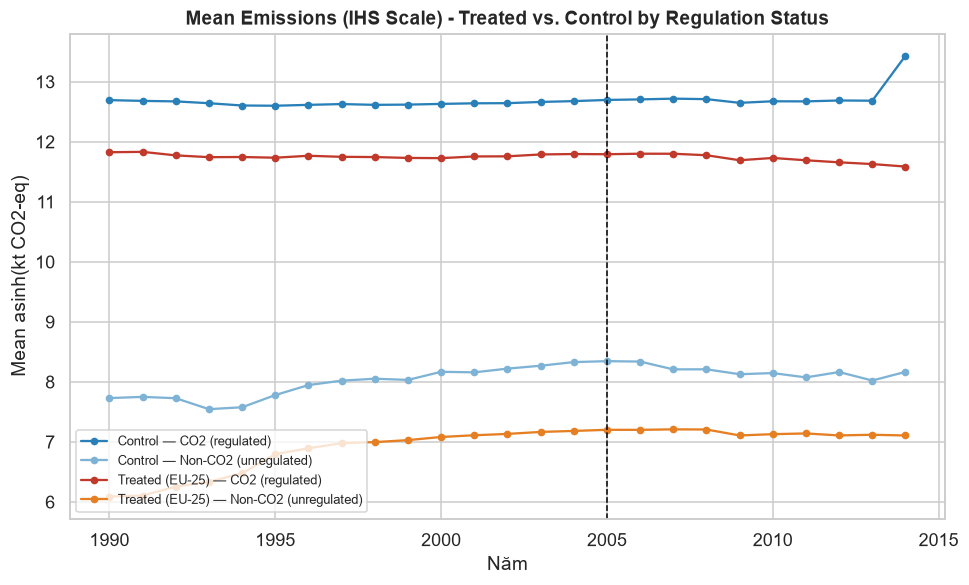

In [17]:
grp = (df_baseline.groupby(["year", "treated", "regulated"])["y_ihs"]
                    .mean().reset_index())
grp["group"] = grp.apply(lambda r: f"{'Treated (EU-25)' if r.treated else 'Control'} — "
                                    f"{'CO2 (regulated)' if r.regulated else 'Non-CO2 (unregulated)'}", axis=1)

fig, ax = plt.subplots(figsize=(9, 5.5))
palette = {"Treated (EU-25) — CO2 (regulated)": "#c0392b",
           "Treated (EU-25) — Non-CO2 (unregulated)": "#e67e22",
           "Control — CO2 (regulated)": "#2980b9",
           "Control — Non-CO2 (unregulated)": "#7fb3d5"}
for g, sub in grp.groupby("group"):
    ax.plot(sub.year, sub.y_ihs, marker="o", markersize=4, label=g, color=palette[g])
ax.axvline(2005, color="black", linestyle="--", linewidth=1)
ax.set_title("Mean Emissions (IHS Scale) - Treated vs. Control by Regulation Status")
ax.set_ylabel("Mean asinh(kt CO2-eq)"); ax.set_xlabel("Năm")
ax.legend(fontsize=8.5, loc="lower left")
plt.tight_layout()
plt.show()


**Reading the plot:** If the EU ETS has a different effect on CO₂ emissions, the **“Treated - CO₂”** line may start to move differently from the other three lines after 2005, for example, by declining faster. However, this is only an **initial visual comparison** and does not by itself show that the EU ETS caused the change. The effect will be formally tested in **Steps 4–5** using a **DDD model** with appropriate **fixed effects**.


# Step 4 - Triple-Difference Model

The DDD model is used to examine whether the **EU ETS had a different effect on CO₂ emissions in EU countries after 2005**.

$$
Y_{igt}
=
\beta(Treated_i \times Post_t \times Regulated_g)
+
\alpha_{ig}
+
\gamma_{it}
+
\delta_{gt}
+
\varepsilon_{igt}
$$

Where:

* **`Treated × Post × Regulated`** is the key variable of interest. The coefficient $\beta$ measures the change in **EU ETS-regulated emissions (CO₂)** for the **Treatment group after 2005**, after accounting for other changes.

* **`country × gas` FE ($\alpha_{ig}$):** controls for fixed differences between countries and gases, such as their different baseline emission levels.

* **`country × year` FE ($\gamma_{it}$):** controls for factors that change over time within each country, such as economic growth, economic crises, or domestic energy policies.

* **`gas × year` FE ($\delta_{gt}$):** controls for changes affecting each gas over time, such as technological changes or global fuel-price trends.

By including all three sets of fixed effects, the model controls for many factors that may affect emissions. Therefore, the **three-way interaction `Treated × Post × Regulated` provides the main source of identification for the EU ETS effect**.

**Standard errors** are **clustered at the country level**, because treatment is assigned at the country level and errors may be correlated across years within the same country.


In [18]:
def fit_ddd(df, rhs="ddd", vcov=None):
    vcov = vcov or {"CRV1": "country"}
    m = pf.feols(
        f"y_ihs ~ {rhs} | country_gas + country_year + gas_year",
        data=df,
        vcov=vcov
    )
    return m


# (1) Naive specification: one-way fixed effects
m_naive = pf.feols(
    "y_ihs ~ ddd | country + year + gas",
    data=df_baseline,
    vcov={"CRV1": "country"}
)

# (2) Baseline specification: two-way fixed effects
m_baseline = fit_ddd(df_baseline)


# Regression results
pf.etable(
    [m_naive, m_baseline],
    labels={
        "ddd": "EU ETS effect (Treated × Post × Regulated)"
    },
    model_heads=[
        "(1) Naive Model",
        "(2) Baseline DDD Model"
    ],
    fitstat=[
        "n",
        "r2"
    ]
)

GT(_tbl_data=  __index_level_0__                           __index_level_1__                    0                    1
0              coef  EU ETS effect (Treated × Post × Regulated)  -0.212 <br> (0.143)  -0.209 <br> (0.196)
1                fe                               country_year                     -                    x
2                fe                                         gas                    x                    -
3                fe                                    gas_year                    -                    x
4                fe                                       year                     x                    -
5                fe                                    country                     x                    -
6                fe                                country_gas                     -                    x
7             stats                                Observations                5,247                5,247
8             stats                                          R²                0.862                0.967, _body=<great_tables._gt_data.Body object at 0x0000023DBF184D40>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align='center', column_width=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label='(1)', column_align='center', column_width=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label='(2)', column_align='center', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x0000023DBF291340>, _spanners=Spanners([SpannerInfo(spanner_id='y_ihs', spanner_level=2, spanner_label='y_ihs', spanner_units=None, spanner_pattern=None, vars=['0', '1'], built=None), SpannerInfo(spanner_id='(1) Naive Model', spanner_level=1, spanner_label='(1) Naive Model', spanner_units=None, spanner_pattern=None, vars=['0'], built=None), SpannerInfo(spanner_id='(2) Baseline DDD Model', spanner_level=1, spanner_label='(2) Baseline DDD Model', spanner_units=None, spanner_pattern=None, vars=['1'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x0000023DBF291130>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x0000023DBF292450>, _source_notes=['Significance levels: * p < 0.05, ** p < 0.01, *** p < 0.001. Format of coefficient cell: Coefficient   (Std. Error)'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x0000023DBF2910A0>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=O

**Baseline Results**

The DDD coefficient in Model (2) is the main estimate used in the study. The sign and magnitude of the coefficient indicate whether CO₂ (the regulated gas) decreased faster, in a statistically significant way, in the EU-25 after 2005, compared with the pre-existing difference between CO₂ and the other gases in the Control group.

Comparing Model (1) with Model (2) shows how the DDD coefficient changes when the model includes the full set of two-way interactions. If the coefficients differ substantially between the two models, this suggests that Model (1) may be affected by country- and gas-specific trends, which are accounted for in Model (2).


# Step 5 — Parallel Trends & Event Study

The event-study version of the DDD model replaces the single `Post` indicator with **year-specific indicators**, using **2004** as the reference year because it is the year immediately before the EU ETS started:

$$
Y_{igt}
=
\sum_{\tau \neq 2004}
\beta_\tau
\left(
Treated_i \times Regulated_g \times \mathbb{1}[t=\tau]
\right)
+
\alpha_{ig}
+
\gamma_{it}
+
\delta_{gt}
+
\varepsilon_{igt}
$$

The same three sets of fixed effects from Step 4 are included. Each $\beta_\tau$ shows how the **EU-25 CO₂ outcome differs relative to the Control group in year $\tau$, compared with 2004**.

For the **pre-treatment years ($\tau < 2005$)**, the coefficients should be **close to zero and statistically insignificant**. This provides evidence that the **parallel-trends assumption** is reasonable before the EU ETS began.


In [31]:
def event_study(df, ref=2004, vcov=None):

    vcov = vcov or {"CRV1": "country"}

    m = pf.feols(
        f"y_ihs ~ i(year, treated*regulated, ref={ref}) | "
        f"country_gas + country_year + gas_year",
        data=df,
        vcov=vcov
    )

    return m


def joint_pretrend_test(m, cutoff=2005):

    tidy = m.tidy()

    pre = [
        c for c in tidy.index
        if c.startswith("year::")
        and int(c.split("::")[1].split(":")[0]) < cutoff
    ]

    names = list(tidy.index)

    R = np.zeros((len(pre), len(names)))

    for i, c in enumerate(pre):
        R[i, names.index(c)] = 1

    res = m.wald_test(
        R=R,
        q=np.zeros(len(pre)),
        distribution="F"
    )

    return pre, res


def event_coef_df(m):

    tidy = m.tidy().reset_index().rename(
        columns={"Coefficient": "term"}
    )

    tidy = tidy[
        tidy.term.str.startswith("year::")
    ].copy()

    tidy["event_year"] = (
        tidy.term
        .str.extract(r"year::(\d+):")
        .astype(int)
    )

    tidy = tidy.sort_values("event_year")

    row2004 = pd.DataFrame({
        "event_year": [2004],
        "Estimate": [0.0],
        "2.5%": [0.0],
        "97.5%": [0.0]
    })

    out = pd.concat([
        tidy[["event_year", "Estimate", "2.5%", "97.5%"]],
        row2004
    ]).sort_values("event_year")

    return out.reset_index(drop=True)


m_event = event_study(df_baseline)

pre_terms, pretrend_res = joint_pretrend_test(m_event)

f_stat = pretrend_res["statistic"]
p_value = pretrend_res["pvalue"]

print("=" * 60)
print("JOINT PRE-TREND TEST")
print("=" * 60)

print(f"Number of pre-treatment coefficients: {len(pre_terms)}")
print("Reference year: 2004")
print("Policy start year: 2005")
print(f"F-statistic: {f_stat:.2f}")
print(f"P-value: {p_value:.4f}")

print("\nHypotheses:")
print(f"H0: All {len(pre_terms)} pre-2005 coefficients are jointly equal to 0.")
print("H1: At least one pre-2005 coefficient is different from 0.")

if p_value < 0.05:
    print("\nResult: REJECT H0 (p < 0.05)")
    print("Interpretation:")
    print("There is significant evidence of pre-treatment differences/trends")
    print("before 2005. The parallel-trends assumption may be violated.")
else:
    print("\nResult: FAIL TO REJECT H0 (p >= 0.05)")
    print("Interpretation:")
    print("There is no significant evidence of pre-treatment differences/trends")
    print("before 2005. The result is consistent with the parallel-trends assumption.")

print("=" * 60)

JOINT PRE-TREND TEST
Number of pre-treatment coefficients: 14
Reference year: 2004
Policy start year: 2005
F-statistic: 70.36
P-value: 0.0000

Hypotheses:
H0: All 14 pre-2005 coefficients are jointly equal to 0.
H1: At least one pre-2005 coefficient is different from 0.

Result: REJECT H0 (p < 0.05)
Interpretation:
There is significant evidence of pre-treatment differences/trends
before 2005. The parallel-trends assumption may be violated.


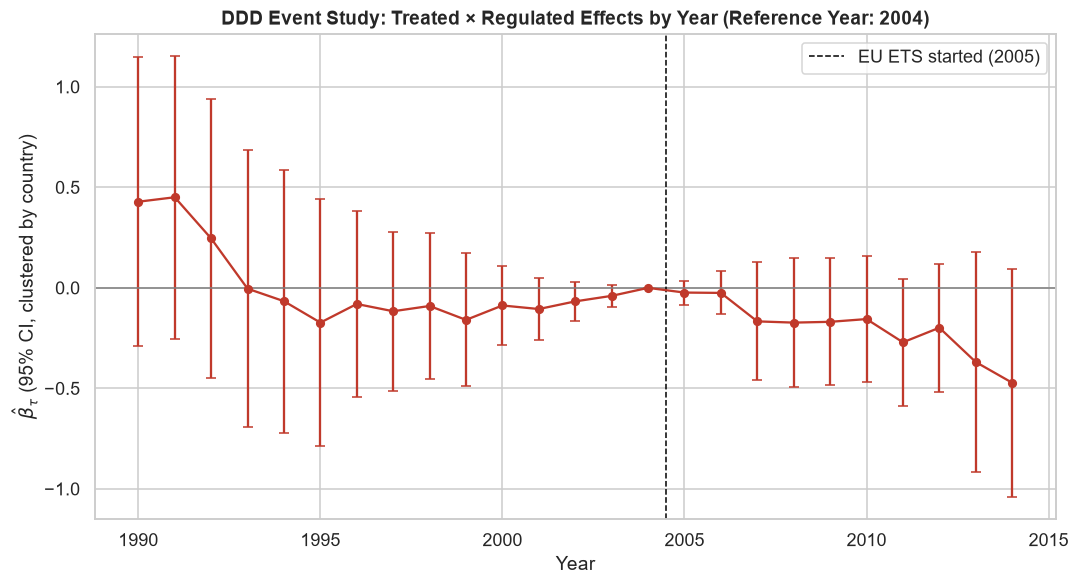

In [37]:
ev = event_coef_df(m_event)

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.errorbar(
    ev.event_year,
    ev.Estimate,
    yerr=[
        ev.Estimate - ev["2.5%"],
        ev["97.5%"] - ev.Estimate
    ],
    fmt="o-",
    capsize=3,
    color="#c0392b",
    ecolor="#c0392b",
    markersize=5
)

ax.axhline(0, color="grey", linewidth=1)

ax.axvline(
    2004.5,
    color="black",
    linestyle="--",
    linewidth=1,
    label="EU ETS started (2005)"
)

ax.set_title(
    "DDD Event Study: Treated × Regulated Effects by Year "
    "(Reference Year: 2004)"
)

ax.set_xlabel("Year")
ax.set_ylabel(r"$\hat{\beta}_{\tau}$ (95% CI, clustered by country)")

ax.legend()

plt.tight_layout()
plt.show()

**Observation**
The event-study estimates show substantial variation in the pre-treatment period, with several coefficients differing from zero. Consistent with the joint pre-trend test (F = 70.36, p < 0.001), this indicates statistically significant pre-treatment differences and raises concerns about the parallel-trends assumption. After 2005, the estimated coefficients become increasingly negative, although several 95% confidence intervals include zero.

## 5.1 Concern About "Economies in Transition" and Robustness to the Pre-Treatment Window

The Appendix I sample includes post-Soviet **economies in transition**, particularly **Belarus, Russia, and Ukraine**. These countries experienced very large declines in CO₂ emissions during the early 1990s following the collapse of the Soviet Union.

These shocks occurred **before the EU ETS was introduced and were unrelated to the EU ETS**, but they may affect the joint pre-trend test when the full **1990–2004** pre-treatment period is used.

To examine whether the pre-trend results are driven by these early-1990s shocks, we progressively **shorten the pre-treatment window** and re-estimate the joint pre-trend test.

For example:

```text
1990–2004
   ↓
1992–2004
   ↓
1995–2004
   ↓
1998–2004
   ↓
2000–2004

The purpose of this robustness check is to determine whether the evidence of pre-treatment differences remains when the analysis focuses on years closer to the introduction of the EU ETS in 2005.

If the pre-trend evidence becomes substantially weaker after excluding the early 1990s, this would suggest that the original result may be partly driven by the large economic shocks experienced by the transition economies during that period. If significant pre-trends remain in shorter windows, this would indicate that the issue is not limited to the early-1990s shocks.


In [38]:
rows = []
for start in [1990, 1995, 2000]:
    df_w = add_treatment(panel_sample, {c: 2005 for c in EU25}, BASELINE_CONTROL, 2005,
                          REGULATED_BASELINE, sample_start=start)
    m_w = event_study(df_w)
    pre_w, res_w = joint_pretrend_test(m_w)
    rows.append({"pre_period_start": start, "n_pre_coefs": len(pre_w),
                 "test_stat": res_w["statistic"], "p_value": res_w["pvalue"]})
pretrend_sensitivity = pd.DataFrame(rows)
pretrend_sensitivity


,pre_period_start,n_pre_coefs,test_stat,p_value
0,1990,14,70.361489,1.659876e-09
1,1995,9,15.801710,7.113966e-02
2,2000,4,4.187366,3.812421e-01


**Interpretation.** The evidence of pre-treatment differences is sensitive to the choice of the pre-treatment window. When the window is shortened from 1990–2004 to 1995–2004 and 2000–2004, the p-value increases from below 0.001 to 0.071 and 0.381, respectively, and the joint test no longer rejects the null hypothesis at the 5% significance level.

This pattern is consistent with the possibility that the strong pre-trend evidence in the full 1990–2004 window is partly driven by large economic shocks affecting the post-Soviet transition economies during the early 1990s. However, this sensitivity analysis does not by itself establish that these shocks are the sole source of the pre-trend evidence, nor does it directly rule out other sources of pre-treatment differences.

This is an important limitation for the causal interpretation of the event-study estimates and should be discussed in Step 8. Therefore, the notebook reports both the full pre-treatment window and the narrower windows as part of the robustness analysis.

# Step 6 - Robustness Checks

We assess the sensitivity of the baseline DDD estimate along six dimensions:

1. **Treatment timing and corresponding gas coverage**  
   Vary the treatment year and the corresponding set of regulated gases to examine whether the results depend on the baseline definition of policy exposure.

2. **Alternative definitions of "regulated" gases**  
   Change the classification of regulated gases to assess whether the DDD estimate is sensitive to how gas coverage is defined.

3. **Leave-one-country-out analysis**  
   Re-estimate the model after excluding one country at a time, with particular attention to large economies. This tests whether the results are driven disproportionately by any single country.

4. **Placebo treatment years before 2005**  
   Assign hypothetical treatment years before the actual EU ETS implementation in 2005 and re-estimate the model. This checks whether similar effects appear at dates when the policy was not yet in place.

5. **Alternative control groups**  
   Replace the baseline control group with alternative control groups to assess whether the results depend on the choice of comparison group.

6. **Alternative clustering of standard errors**  
   Use alternative clustering specifications to examine whether statistical inference is sensitive to how standard errors are estimated.

All robustness checks retain the **same saturated fixed-effects specification as in Step 4**, including `country_gas`, `country_year`, and `gas_year` fixed effects. The purpose is to change one modeling choice at a time while keeping the core identification framework unchanged.

Overall, these checks assess whether the baseline DDD result is stable across alternative treatment definitions, gas classifications, country compositions, placebo timings, control groups, and inference procedures.


In [40]:
robustness_rows = []

def add_row(label, m, extra=None):
    t = m.tidy().loc["ddd"]
    row = {"specification": label, "beta": t["Estimate"], "se": t["Std. Error"],
           "p_value": t["Pr(>|t|)"], "ci_low": t["2.5%"], "ci_high": t["97.5%"]}
    if extra: row.update(extra)
    robustness_rows.append(row)

# --- (0) Repeat the baseline specification for comparison ---
add_row("(0) Baseline: EU-25 vs control, treat=2005, Regulated={CO2}", m_baseline)


## 6.1 Varying Treatment Years and Gas Coverage According to the Legal Timeline

In [41]:
# --- (a) Vary treatment year and regulated gases ---

specs_year = [
    # Phase 1: treatment starts in 2005, CO2 is regulated
    ("Treatment year = 2005 (Phase 1), Regulated = {CO2}",
     2005, REGULATED_BASELINE),

    # Phase 2: treatment starts in 2008, CO2 is regulated
    ("Treatment year = 2008 (Phase 2), Regulated = {CO2}",
     2008, REGULATED_BASELINE),

    # Phase 3: treatment starts in 2013, CO2, N2O and PFCs are regulated
    ("Treatment year = 2013 (Phase 3), Regulated = {CO2, N2O, PFCs}",
     2013, REGULATED_PHASE3),
]

for label, tyear, reg in specs_year:

    # Rebuild the treatment variable using the selected year and gases
    df_s = add_treatment(
        panel_sample,
        {c: tyear for c in EU25},
        BASELINE_CONTROL,
        tyear,
        reg
    )

    # Re-estimate the DDD model
    m_s = fit_ddd(df_s)

    # Save the DDD coefficient and statistical results
    add_row(label, m_s)

# Show results for the three specifications
pd.DataFrame(robustness_rows)[
    ["specification", "beta", "se", "p_value"]
].tail(3)

,specification,beta,se,p_value
1,"Treatment year = 2005 (Phase 1), Regulated = {...",-0.209441,0.195721,0.291898
2,"Treatment year = 2008 (Phase 2), Regulated = {...",-0.251657,0.186529,0.185952
3,"Treatment year = 2013 (Phase 3), Regulated = {...",-0.025988,0.321210,0.935976


## 6.2 Varying the Definition of "Regulated" Gases (Holding the Treatment Year at 2005)

In [42]:
# --- (b) Vary the definition of regulated gases (treatment year = 2005) ---

specs_class = [
    # Baseline: CO2 is regulated
    ("(b) Regulated = {CO2} (Phase 1 baseline)",
     {"CO2"}),

    # Alternative: assume N2O was regulated from 2005
    ("(b) Regulated = {CO2, N2O} (N2O regulated earlier)",
     {"CO2", "N2O"}),

    # Alternative: assume Phase 3 gas coverage applied from 2005
    ("(b) Regulated = {CO2, N2O, PFCs} (Phase 3 coverage from 2005)",
     {"CO2", "N2O", "PFCs"}),
]

for label, reg in specs_class:

    # Rebuild treatment using the same treatment year but different regulated gases
    df_s = add_treatment(
        panel_sample,
        {c: 2005 for c in EU25},
        BASELINE_CONTROL,
        2005,
        reg
    )

    # Re-estimate the DDD model
    m_s = fit_ddd(df_s)

    # Save the results
    add_row(label, m_s)

# Display the results for the three specifications
pd.DataFrame(robustness_rows)[
    ["specification", "beta", "se", "p_value"]
].tail(3)

,specification,beta,se,p_value
4,(b) Regulated = {CO2} (Phase 1 baseline),-0.209441,0.195721,0.291898
5,"(b) Regulated = {CO2, N2O} (N2O regulated earl...",-0.332008,0.215088,0.131682
6,"(b) Regulated = {CO2, N2O, PFCs} (Phase 3 cove...",0.204874,0.446997,0.649545


## 6.3 Leave-One-Country-Out Analysis (Major Economies)

In [43]:
# --- (c) Leave-one-country-out analysis ---

BIG_ECONOMIES = [
    "Germany",
    "United Kingdom",
    "Russian Federation",
    "United States of America"
]

for c_drop in BIG_ECONOMIES:

    # Remove one country from the treated group
    eu25_loo = [c for c in EU25 if c != c_drop]

    # Remove the same country from the control group if present
    control_loo = [c for c in BASELINE_CONTROL if c != c_drop]

    # Rebuild the treatment variable
    df_s = add_treatment(
        panel_sample,
        {c: 2005 for c in eu25_loo},
        control_loo,
        2005,
        REGULATED_BASELINE
    )

    # Re-estimate the DDD model
    m_s = fit_ddd(df_s)

    # Save the results
    add_row(f"(c) Leave-one-out: exclude {c_drop}", m_s)

# Display the results for the four leave-one-out specifications
pd.DataFrame(robustness_rows)[
    ["specification", "beta", "se", "p_value"]
].tail(4)

,specification,beta,se,p_value
7,(c) Leave-one-out: exclude Germany,-0.229316,0.198142,0.255204
8,(c) Leave-one-out: exclude United Kingdom,-0.239303,0.196693,0.232123
9,(c) Leave-one-out: exclude Russian Federation,-0.179116,0.206322,0.391405
10,(c) Leave-one-out: exclude United States of Am...,-0.161208,0.202055,0.430498


### Interpretation
The estimated DDD coefficient remains negative and relatively close to the baseline estimate when each major economy is excluded from the sample. None of the leave-one-out estimates is statistically significant at the 5% level. This suggests that the baseline estimate is not driven by any single major economy in the leave-one-out specifications.

## 6.4 Placebo Treatment Years (Before 2005, Using Only the Actual Pre-Treatment Data)

We simulate a **placebo policy** that starts in a year *before* the EU ETS was actually introduced, and estimate the model using **only data from before 2005**. Therefore, no actual EU ETS effect should be present in the estimation window.

The DDD coefficient is expected to be **statistically insignificant**. If a significant effect is detected, this may indicate a **spurious pre-treatment trend or systematic differences** that are unrelated to the actual EU ETS policy.


In [44]:
# --- (d) Placebo treatment years: before the actual EU ETS start ---

for fake_year in [1997, 2000]:

    # Create a placebo treatment starting before 2005
    # and use only pre-treatment data up to 2004
    df_s = add_treatment(
        panel_sample,
        {c: fake_year for c in EU25},
        BASELINE_CONTROL,
        fake_year,
        REGULATED_BASELINE,
        sample_end=2004
    )

    # Re-estimate the DDD model
    m_s = fit_ddd(df_s)

    # Save the placebo results
    add_row(
        f"(d) Placebo: fake treatment year = {fake_year}, sample through 2004",
        m_s
    )

# Display the two placebo specifications
pd.DataFrame(robustness_rows)[
    ["specification", "beta", "se", "p_value"]
].tail(2)

,specification,beta,se,p_value
11,"(d) Placebo: fake treatment year = 1997, sampl...",-0.197691,0.220074,0.375168
12,"(d) Placebo: fake treatment year = 2000, sampl...",-0.103541,0.224461,0.647448


### Interpretation

The placebo tests using 1997 and 2000 as hypothetical treatment years produce negative but statistically insignificant DDD estimates. The p-values are 0.375 and 0.647, respectively, both above the 5% significance level.

Therefore, the placebo specifications do not provide evidence of a statistically significant treatment effect before the actual introduction of the EU ETS in 2005. This result is consistent with the absence of a comparable placebo effect in the pre-treatment period.

## 6.5 Changing the Control Group

In [45]:
# --- (e) Change the control group ---

specs_control = [
    # Baseline control group
    ("(e) Control = baseline (11 countries, including transition economies)",
     BASELINE_CONTROL),

    # OECD-only control group
    ("(e) Control = OECD only (excluding Russia/Ukraine/Belarus)",
     OECD_CONTROL),

    # Baseline control group + EEA countries
    ("(e) Control = baseline + EEA (Norway/Iceland/Liechtenstein, treated as never-treated)",
     BASELINE_CONTROL + list(EEA_JOINERS)),
]

for label, ctrl in specs_control:

    # Rebuild the treatment using the selected control group
    df_s = add_treatment(
        panel_sample,
        {c: 2005 for c in EU25},
        ctrl,
        2005,
        REGULATED_BASELINE
    )

    # Re-estimate the DDD model
    m_s = fit_ddd(df_s)

    # Save the results
    add_row(label, m_s)


# --- (e-extra) Staggered-timing extension ---
# Add Bulgaria, Romania, and Croatia using their actual EU ETS entry years

treated_stagger = {
    **{c: 2005 for c in EU25},
    **LATER_JOINERS
}

df_stagger = add_treatment(
    panel_sample,
    treated_stagger,
    BASELINE_CONTROL,
    2005,
    REGULATED_BASELINE
)

m_stagger = fit_ddd(df_stagger)

add_row(
    "(e) Staggered-timing extension: add BG/RO/HR using their actual ETS entry years",
    m_stagger
)


# Display the four specifications
pd.DataFrame(robustness_rows)[
    ["specification", "beta", "se", "p_value"]
].tail(4)

,specification,beta,se,p_value
13,"(e) Control = baseline (11 countries, includin...",-0.209441,0.195721,0.291898
14,(e) Control = OECD only (excluding Russia/Ukra...,-0.359900,0.189882,0.067104
15,(e) Control = baseline + EEA (Norway/Iceland/L...,-0.225204,0.178958,0.215918
16,(e) Staggered-timing extension: add BG/RO/HR u...,-0.213085,0.172813,0.225135


### Interpretation
The DDD estimate remains negative across alternative control-group specifications. The OECD-only specification produces a larger negative coefficient (-0.360) and a p-value of 0.067, while the baseline + EEA and staggered-timing specifications yield estimates close to the baseline. None of the specifications is statistically significant at the 5% level. Overall, the sign of the estimated effect is stable, although its magnitude is somewhat sensitive to the choice of the control group.

## 6.6 Varying the Standard Error Clustering Method (Inference Sensitivity)

With only ~35 country clusters, standard CRV1 clustered standard errors may be somewhat optimistic. We therefore compare them with clustering by gas (6 clusters - for reference only) and heteroskedasticity-robust standard errors (without clustering) to assess the sensitivity of statistical inference, rather than to select the “most favorable” standard errors.


In [46]:
# --- (f) Test different ways of calculating standard errors ---

vcov_specs = [
    # Baseline: cluster standard errors by country
    ("Cluster by country (baseline)", {"CRV1": "country"}),

    # Alternative: cluster standard errors by gas
    # Only for reference because there are only 6 gas clusters
    ("Cluster by gas (reference only, 6 clusters)", {"CRV1": "gas"}),

    # Alternative: heteroskedasticity-robust standard errors without clustering
    ("Heteroskedasticity-robust (no clustering)", "hetero")
]

se_rows = []

for label, vc in vcov_specs:

    # Estimate the same DDD model with a different standard error method
    m_v = pf.feols(
        "y_ihs ~ ddd | country_gas + country_year + gas_year",
        data=df_baseline,
        vcov=vc
    )

    # Get the results for the DDD coefficient
    t = m_v.tidy().loc["ddd"]

    # Save the coefficient, standard error, and p-value
    se_rows.append({
        "vcov": label,
        "beta": t["Estimate"],
        "se": t["Std. Error"],
        "p_value": t["Pr(>|t|)"]
    })

# Compare the results across the three standard error methods
pd.DataFrame(se_rows)

,vcov,beta,se,p_value
0,Cluster by country (baseline),-0.209441,0.195721,0.291898
1,"Cluster by gas (reference only, 6 clusters)",-0.209441,0.202366,0.348123
2,Heteroskedasticity-robust (no clustering),-0.209441,0.087576,0.016824


### Interpretation
The estimated coefficient remains unchanged at -0.209 across all standard error specifications. However, statistical inference is sensitive to the choice of standard errors. Clustering by country and by gas produces similar results, with p-values of 0.292 and 0.348, respectively. In contrast, heteroskedasticity-robust standard errors are substantially smaller and yield a p-value of 0.017. Therefore, the statistical significance of the estimate depends on the standard error specification. Given the panel structure and the limited number of country clusters, the clustered specifications are more relevant for the main inference, while the heteroskedasticity-robust result is reported as a sensitivity check.

## 6.7 Summary of All Robustness Checks

In [47]:
# Create a DataFrame containing all robustness check results
robust_df = pd.DataFrame(robustness_rows)

# Check whether the p-value is below 5%
robust_df["sig_5pct"] = robust_df.p_value < 0.05

# Set the maximum width for the specification column
pd.set_option("display.max_colwidth", 70)

# Display the main results
robust_df[["specification", "beta", "se", "p_value", "sig_5pct"]]


,specification,beta,se,p_value,sig_5pct
0,"(0) Baseline: EU-25 vs control, treat=2005, Regulated={CO2}",-0.209441,0.195721,0.291898,False
1,"Treatment year = 2005 (Phase 1), Regulated = {CO2}",-0.209441,0.195721,0.291898,False
2,"Treatment year = 2008 (Phase 2), Regulated = {CO2}",-0.251657,0.186529,0.185952,False
3,"Treatment year = 2013 (Phase 3), Regulated = {CO2, N2O, PFCs}",-0.025988,0.321210,0.935976,False
4,(b) Regulated = {CO2} (Phase 1 baseline),-0.209441,0.195721,0.291898,False
5,"(b) Regulated = {CO2, N2O} (N2O regulated earlier)",-0.332008,0.215088,0.131682,False
6,"(b) Regulated = {CO2, N2O, PFCs} (Phase 3 coverage from 2005)",0.204874,0.446997,0.649545,False
7,(c) Leave-one-out: exclude Germany,-0.229316,0.198142,0.255204,False
8,(c) Leave-one-out: exclude United Kingdom,-0.239303,0.196693,0.232123,False
9,(c) Leave-one-out: exclude Russian Federation,-0.179116,0.206322,0.391405,False


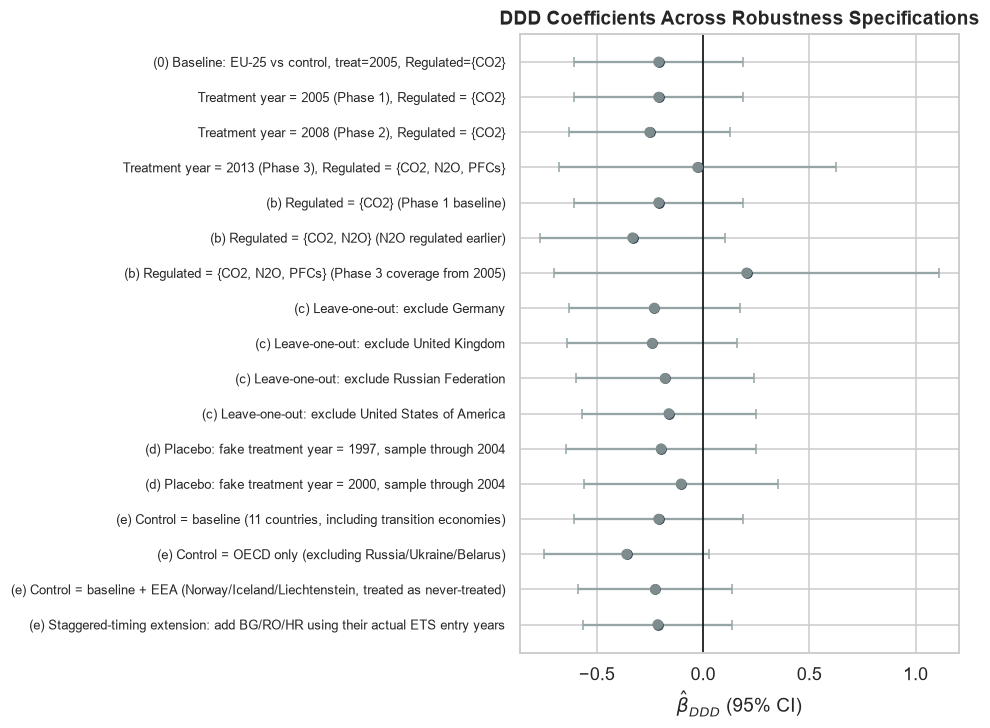

In [50]:
fig, ax = plt.subplots(figsize=(9, max(6, 0.4 * len(robust_df))))
y_pos = np.arange(len(robust_df))[::-1]
colors = ["#c0392b" if s else "#7f8c8d" for s in robust_df.sig_5pct]
ax.errorbar(robust_df.beta, y_pos, xerr=[robust_df.beta - robust_df.ci_low, robust_df.ci_high - robust_df.beta],
            fmt="o", capsize=3, color="#2c3e50", ecolor="#95a5a6")
ax.scatter(robust_df.beta, y_pos, c=colors, zorder=5)
ax.axvline(0, color="black", linewidth=1)
ax.set_yticks(y_pos); ax.set_yticklabels(robust_df.specification, fontsize=8.5)
ax.set_xlabel(r"$\hat\beta_{DDD}$ (95% CI)")
ax.set_title("DDD Coefficients Across Robustness Specifications")
plt.tight_layout()
plt.show()


# Step 7 - Heterogeneity & Interpretation

Instead of grouping all non-CO₂ gases into a single Regulated=0 category, we estimate a separate two-way Difference-in-Differences (DD) model for each gas. Each model includes Treated × Post, controls for country and year fixed effects, and clusters standard errors by country. This allows us to examine whether different gases respond differently after 2005, including gases that were not directly regulated by the EU ETS.

$$Y_{it}^{(g)} = \beta_g\,(Treated_i \times Post_t) + \alpha_i + \gamma_t + \varepsilon_{it} \quad \text{- where each gas $g$ is estimated separately.}


In [51]:
gas_het_rows = []
for g in sorted(df_baseline.gas.unique()):
    sub = df_baseline[df_baseline.gas == g].copy()
    m_g = pf.feols("y_ihs ~ treated:post | country + year", data=sub, vcov={"CRV1": "country"})
    t = m_g.tidy().loc["treated:post"]
    gas_het_rows.append({"gas": g, "beta": t["Estimate"], "se": t["Std. Error"],
                          "p_value": t["Pr(>|t|)"], "ci_low": t["2.5%"], "ci_high": t["97.5%"],
                          "n_obs": len(sub),
                          "eu_ets_status": gas_classification.set_index("gas").loc[g, "eu_ets_status"]})
gas_het = pd.DataFrame(gas_het_rows).sort_values("beta")
gas_het[["gas", "eu_ets_status", "beta", "se", "p_value", "n_obs"]]


,gas,eu_ets_status,beta,se,p_value,n_obs
3,N2O,"Later/partially covered (Phase 3, 2013; NL opt-in 2010)",-0.182187,0.059742,0.004348,899
0,CH4,Not directly covered (Effort Sharing / non-ETS),-0.147640,0.070773,0.044323,899
1,CO2,"Directly covered (Phase 1, 2005)",-0.094992,0.067077,0.165563,899
5,SF6,"Not directly covered (F-Gas Regulation, ngoài ETS)",0.003567,0.408769,0.993087,900
2,HFCs,"Not directly covered (F-Gas Regulation, ngoài ETS)",0.135008,0.716720,0.851707,875
4,PFCs,"Later/partially covered (Phase 3, 2013 — primary aluminium)",0.884525,0.622799,0.165847,775


The gas-level DD estimates reveal heterogeneous post-2005 responses across gases, with statistically significant negative estimates for N2O and CH4, but not for CO2.

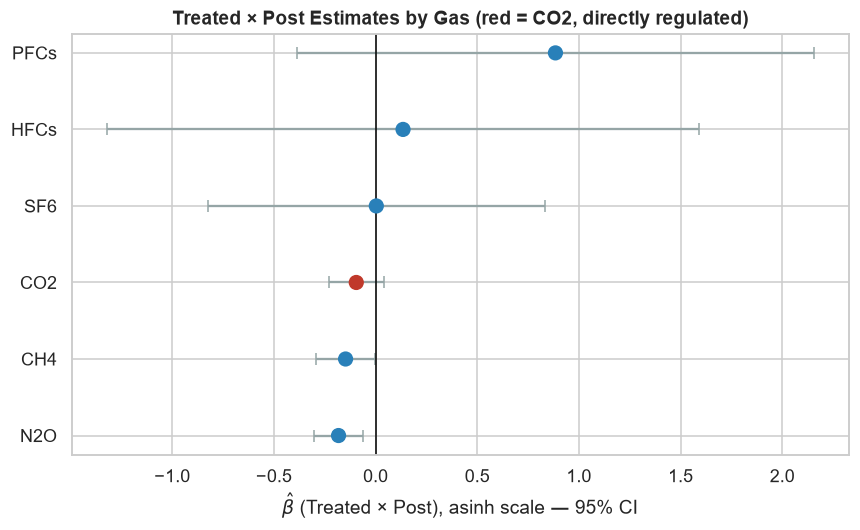

In [54]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#c0392b" if g == "CO2" else "#2980b9" for g in gas_het.gas]
y_pos = np.arange(len(gas_het))
ax.errorbar(gas_het.beta, y_pos, xerr=[gas_het.beta - gas_het.ci_low, gas_het.ci_high - gas_het.beta],
            fmt="o", capsize=4, color="#2c3e50", ecolor="#95a5a6")
ax.scatter(gas_het.beta, y_pos, c=colors, s=80, zorder=5)
ax.axvline(0, color="black", linewidth=1)
ax.set_yticks(y_pos); ax.set_yticklabels(gas_het.gas)
ax.set_xlabel(r"$\hat{\beta}$ (Treated × Post), asinh scale — 95% CI")
ax.set_title("Treated × Post Estimates by Gas (red = CO2, directly regulated)")
plt.tight_layout()

plt.show()

## 7.1 CO₂ vs. the Average of Non-Directly Regulated Gases

We directly compare $\hat{\beta}_{CO_2}$ with the average $\hat{\beta}_g$ across the gases classified as `Regulated=0` (CH₄, HFCs, and SF₆). This provides a more intuitive gas-level interpretation of the baseline DDD coefficient from Step 4.

In [55]:
co2_beta = gas_het.loc[gas_het.gas == "CO2", "beta"].values[0]

non_co2_direct = gas_het[gas_het.gas.isin(["CH4", "HFCs", "SF6"])]

print(f"Beta CO2 (directly regulated gas): {co2_beta:+.3f}")

print(f"Average beta of non-directly regulated gases: {non_co2_direct.beta.mean():+.3f}")

print(f"Beta N2O, PFCs (later/partially covered from 2013): "
      f"{gas_het.loc[gas_het.gas=='N2O','beta'].values[0]:+.3f}, "
      f"{gas_het.loc[gas_het.gas=='PFCs','beta'].values[0]:+.3f}")


Beta CO2 (directly regulated gas): -0.095
Average beta of non-directly regulated gases: -0.003
Beta N2O, PFCs (later/partially covered from 2013): -0.182, +0.885


## 7.2 Interpretation

The results show that **emission responses are heterogeneous across gases** after 2005. The magnitude, direction, and statistical significance of the estimates differ substantially across gases, and the pattern does **not necessarily follow the simple expectation that directly regulated gases should decline more strongly**.

The results should therefore be interpreted cautiously:

- If the DDD estimate in Step 4 were negative, statistically significant, and robust across the specifications in Step 6, this would provide evidence of **heterogeneous emission responses across gases**, consistent with the hypothesis that the selective regulatory coverage of the EU ETS creates different incentives for reducing different gases.

- However, the analysis does **not provide sufficient evidence to conclude that there is "internal leakage"**, meaning that emissions are shifted from regulated gases to non-regulated gases within the same facility or production process. Establishing such a mechanism would require facility- or industry-level data that can directly identify substitution between gases within the same production process. The country-level data used in this notebook cannot identify this mechanism.

- Heterogeneous responses may also reflect **non-ETS policies and other factors occurring at the same time**, such as the F-Gas Regulation, Effort Sharing policies, and technological changes in agriculture, rather than the EU ETS alone.

- The relatively limited sample size (~35 countries, 6 gases, and 25 years) and sparse observations for some minor gases, particularly PFCs and HFCs, also limit statistical power. The wide confidence intervals in several specifications in Step 6 reflect this limitation. Therefore, **a statistically insignificant estimate should not be interpreted as evidence of no effect**.

Overall, the gas-level results provide evidence of **heterogeneous post-2005 emission responses across gases**. However, because the baseline DDD estimate is not statistically significant and the robustness checks do not establish a statistically robust overall EU ETS effect, these heterogeneous estimates should be interpreted as **evidence of differential gas-level responses rather than definitive evidence of a causal EU ETS effect**.

# Step 8 - Main Outputs
This section summarizes the **six main outputs** of the analysis, with each output linked to the corresponding section completed above.



In [58]:
print("=" * 78)

print("MAIN RESULTS SUMMARY")

print("=" * 78)

print(f"\n[1] Descriptive emission trends -> Step 1.2")

print(f"\n[2] Baseline DDD regression -> Step 4")

t_base = m_baseline.tidy().loc["ddd"]

print(f"    beta_DDD = {t_base['Estimate']:+.3f}  (SE={t_base['Std. Error']:.3f}, "
      f"p={t_base['Pr(>|t|)']:.3f}, N={m_baseline._N})")

print(f"\n[3] DDD event-study results -> Step 5")

print(f"    Joint pre-trend test (full window 1990-2004): "
      f"stat={pretrend_res['statistic']:.2f}, p={pretrend_res['pvalue']:.4f}")

print(f"    -> See Table 5.1 for how the p-value changes when the pre-treatment window is narrowed")

print(f"\n[4] Gas-specific treatment effects -> Step 7")

print(gas_het[["gas","beta","p_value"]].to_string(index=False))

print(f"\n[5] Robustness & placebo results -> Step 6")

print(f"    {len(robust_df)} specifications, {robust_df.sig_5pct.sum()}/{len(robust_df)} statistically significant at the 5% level")

print(f"\n[6] Policy implications -> Section 8.1 below")

MAIN RESULTS SUMMARY

[1] Descriptive emission trends -> Step 1.2

[2] Baseline DDD regression -> Step 4
    beta_DDD = -0.209  (SE=0.196, p=0.292, N=5247)

[3] DDD event-study results -> Step 5
    Joint pre-trend test (full window 1990-2004): stat=70.36, p=0.0000
    -> See Table 5.1 for how the p-value changes when the pre-treatment window is narrowed

[4] Gas-specific treatment effects -> Step 7
 gas      beta  p_value
 N2O -0.182187 0.004348
 CH4 -0.147640 0.044323
 CO2 -0.094992 0.165563
 SF6  0.003567 0.993087
HFCs  0.135008 0.851707
PFCs  0.884525 0.165847

[5] Robustness & placebo results -> Step 6
    17 specifications, 0/17 statistically significant at the 5% level

[6] Policy implications -> Section 8.1 below


## 8.1 Policy Implications

1. **The regulated gas scope determines where emissions reductions occur.** The fact that the EU ETS primarily generated reduction incentives for $\text{CO}_2$ during its first eight years (2005–2012) left major non-$\text{CO}_2$ emission sources (such as industrial $\text{N}_2\text{O}$ or PFCs from aluminum production) unexposed to equivalent carbon pricing. Expanding this scope in Phase 3 (from 2013) was a rational policy adjustment; furthermore, the event-study analysis (Step 5) helps determine whether the emissions response "caught up" immediately following the scope expansion.
2. **Carbon pricing design must be coordinated with non-ETS policy instruments.** Complementary targeted regulations (such as the F-Gas Regulation for $\text{HFCs}/\text{SF}_6$ or the Effort Sharing Decision for agricultural $\text{CH}_4$) are necessary to prevent regulatory loopholes. The observed heterogeneous responses across gases (Step 7) reflect the distinct impact margins of each instrument, although aggregated data precludes isolating the independent contribution of each specific policy.
3. **Lessons for emerging carbon pricing mechanisms expanding gas/sector coverage.** For systems currently broadening their scope (such as the EU ETS2 for buildings & transport, CBAM, or emerging ETS frameworks across Asia), historical insights from EU ETS Phases 1–3 suggest **designing a broad and explicit gas scope from the outset**, rather than adopting a piecemeal expansion. Incremental expansions risk creating temporary "regulatory gaps"—a phenomenon that this DDD empirical model explicitly seeks to quantify.
4. **Interpreting policy lessons alongside research limitations.** The above policy implications should be read in conjunction with the analytical constraints outlined in Section 8.2—specifically, the reliance on national-level aggregated data, which prevents the verification of specific "internal leakage" mechanisms.

## 8.2 Research Limitations

* **National-level data without sector or facility resolution:** This limitation precludes direct empirical testing of "internal leakage" mechanisms (e.g., a facility shifting technology from $\text{CO}_2$-emitting processes to $\text{N}_2\text{O}/\text{PFC}$-emitting processes to evade the ETS); consequently, the analysis remains restricted to observing macro-level correlations.
* **Confounding from economies in transition:** The joint pre-trend test across the full 1990–2004 period is affected by post-Soviet economic restructuring shocks in Russia, Ukraine, and Belarus. This issue is transparently documented in Step 5.1, and it is recommended to interpret these results alongside specifications using narrowed pre-treatment windows.
* **Moderate number of clusters (~35 countries):** Although standard error sensitivity was cross-checked in Step 6.6 for cluster-robust inference, a full Wild Cluster Bootstrap procedure could not be executed due to computational environment constraints.
* **Exclusion of $\text{NF}_3$ and HFC/PFC mixtures:** Due to severe data sparsity (Step 1), these gases were dropped from the main estimation sample; hence, the results do not reflect the dynamics of these specific compounds.
* **Properties of the Inverse Hyperbolic Sine (IHS / arcsinh) transformation:** While the IHS transformation effectively handles true zero values, the estimated coefficients approximate percentage changes only for sufficiently large values. Caution is required when interpreting the absolute magnitude of $\hat{\beta}$, particularly for gases with a high frequency of near-zero observations ($\text{PFCs}$, $\text{HFCs}$, $\text{SF}_6$).
* **Uniform treatment timing assumption at baseline:** The baseline specification assumes a simultaneous treatment start across the EU-25 in 2005. Although a staggered-timing extension test in Step 6.5 yielded consistent estimates, advanced staggered-DiD estimators (e.g., Callaway–Sant'Anna or Sun–Abraham) were not implemented as they exceed the scope of the present three-dimensional DDD framework.